# 03 · Índice de preço real, comparando iguais com iguais

**Projeto:** Apex Imóveis — priorização de segmentos residenciais para um piloto de prospecção.

**Pergunta central do contrato:** quais segmentos de apartamentos apresentam atividade transacional recorrente e preços de referência confiáveis, mesmo depois de corrigir inflação e composição?

**Neste notebook:**
1. Calculamos quanto o preço real por m² variou de 2022 a 2025 **comparando apartamentos parecidos** (mesmo tamanho e mesmo setor).
2. Medimos a **incerteza** do resultado.
3. Testamos se a conclusão **resiste** a escolhas razoáveis.

> **[NOTEBOOK]** porque estamos explorando e testando o método, não executando uma regra fixa.

**Ressalvas:** (a) o R$/m² usa a área construída, que inclui áreas comuns; (b) "real" aqui significa acima do IPCA, a inflação geral, e não a dos imóveis; (c) o valor é o declarado ao fisco.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_colwidth", None)

candidatos = [Path.cwd(), *Path.cwd().parents]
raiz = next((p for p in candidatos if (p / "src" / "database.py").exists()), None)
assert raiz is not None, f"Não achei src/database.py a partir de {Path.cwd()}. O notebook está dentro de apex-imoveis?"
sys.path.append(str(raiz / "src"))

from database import get_engine

engine = get_engine()


def consulta(sql: str) -> pd.DataFrame:
    return pd.read_sql(sql, engine)


def milhar(n) -> str:
    return f"{n:,.0f}".replace(",", ".")

## 1. Carregar e preparar

Carregamos o recorte da janela de análise e criamos as colunas que o índice precisa: faixa de área, ano, trimestre e o logaritmo do preço.

In [2]:
df = consulta("""
    SELECT data_transacao, mes_transacao, ano_transacao, setor_fiscal, area_construida,
           preco_m2_nominal, preco_m2_real, preco_m2_base_nominal, fator_ipca
    FROM analytics.vw_apto_recorte
    WHERE na_janela_analise AND NOT sem_deflator
""")

df["data_transacao"] = pd.to_datetime(df["data_transacao"])
df["mes_transacao"] = pd.to_datetime(df["mes_transacao"])
for col in ["area_construida", "preco_m2_nominal", "preco_m2_real", "preco_m2_base_nominal", "fator_ipca"]:
    df[col] = df[col].astype(float)

df["preco_m2_base_real"] = df["preco_m2_base_nominal"] * df["fator_ipca"]
df["faixa_area"] = pd.cut(
    df["area_construida"],
    bins=[0, 50, 80, 120, 200, np.inf],
    labels=["ate_50", "50_80", "80_120", "120_200", "acima_200"],
).astype(str)
df["ano"] = df["ano_transacao"].astype(str)
df["trimestre"] = df["data_transacao"].dt.to_period("Q").astype(str)
df["log_preco"] = np.log(df["preco_m2_real"])
df["log_preco_base"] = np.log(df["preco_m2_base_real"].where(df["preco_m2_base_real"] > 0))

print(f"{milhar(len(df))} linhas | {df['setor_fiscal'].nunique()} setores | {df['trimestre'].nunique()} trimestres")
df[["ano", "trimestre", "faixa_area", "log_preco"]].head(3)

222.295 linhas | 236 setores | 16 trimestres


,ano,trimestre,faixa_area,log_preco
0,2024,2024Q1,120_200,8.714272
1,2024,2024Q1,acima_200,8.566852
2,2024,2024Q1,acima_200,8.827640


## 2. Como o índice é calculado (em linguagem simples)

Três coisas fazem o preço por m² variar de uma transação para outra: **onde** o imóvel está (setor), **quão grande** ele é (faixa de área) e **quando** foi vendido (ano). Só a última nos interessa.

O método:
1. Usamos o **logaritmo** do preço real. Diferenças de logaritmo são, aproximadamente, variações percentuais.
2. Cada transação recebe "degraus": um para o ano em que foi vendida e um para a faixa de área.
3. Para neutralizar o setor, subtraímos de cada preço **a média do seu setor**. Assim, só se compara cada apartamento com outros do mesmo setor.
4. Um ajuste de **mínimos quadrados** estima o tamanho de cada degrau de ano, já descontados setor e tamanho.
5. `exp(degrau) × 100` dá o índice: o primeiro ano vale 100.

Se o índice sobe, é porque apartamentos **do mesmo setor e do mesmo tamanho** foram vendidos por mais, em termos reais, nos anos mais recentes.

In [3]:
def montar_matriz(d, tempo, usar_setor):
    X = pd.concat(
        [
            pd.get_dummies(d[tempo], prefix="t", drop_first=True, dtype=float),
            pd.get_dummies(d["faixa_area"], prefix="f", drop_first=True, dtype=float),
        ],
        axis=1,
    )
    if not usar_setor:
        X.insert(0, "const", 1.0)  
    return X


def ajustar(X, y, setor, usar_setor):
    M, y = X.to_numpy(), np.asarray(y)
    if usar_setor:
        y = y - pd.Series(y).groupby(setor).transform("mean").to_numpy()
        M = M - pd.DataFrame(M).groupby(setor).transform("mean").to_numpy()
    beta, *_ = np.linalg.lstsq(M, y, rcond=None)
    return pd.Series(beta, index=X.columns)


def indice(d, tempo, usar_setor=True, y="log_preco"):
    X = montar_matriz(d, tempo, usar_setor)
    beta = ajustar(X, d[y].to_numpy(), d["setor_fiscal"].to_numpy(), usar_setor)
    degraus = pd.Series(0.0, index=sorted(d[tempo].unique()))
    for coluna in X.columns:
        if coluna.startswith("t_"):
            degraus[coluna[2:]] = beta[coluna]
    return np.exp(degraus) * 100

## 3. De onde vem a valorização aparente?

Comparamos três versões do mesmo índice real (2022 = 100): a mediana simples, o índice que controla só o tamanho e o que controla tamanho **e** setor.

In [4]:
base_2022 = df.loc[df["ano"] == "2022", "preco_m2_real"].median()

comparacao = pd.DataFrame({
    "mediana simples": df.groupby("ano")["preco_m2_real"].median() / base_2022 * 100,
    "controla tamanho": indice(df, "ano", usar_setor=False),
    "controla tamanho e setor": indice(df, "ano", usar_setor=True),
})

print(f"Variação real {comparacao.index[0]}→{comparacao.index[-1]}:")
for nome, valor in (comparacao.iloc[-1] - 100).items():
    print(f"  {nome:<26} {valor:+.1f}%")
comparacao.round(1)

Variação real 2022→2025:
  mediana simples            +5.2%
  controla tamanho           +4.3%
  controla tamanho e setor   +1.4%


,mediana simples,controla tamanho,controla tamanho e setor
2022,100.0,100.0,100.0
2023,102.0,101.1,100.5
2024,104.7,104.0,102.0
2025,105.2,104.3,101.4


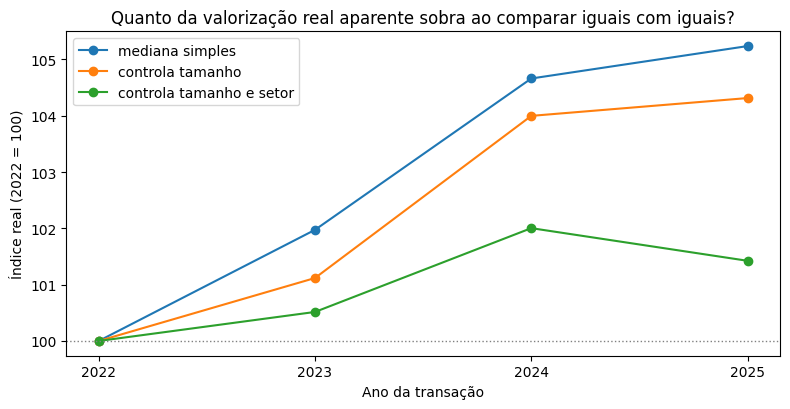

In [5]:
ax = comparacao.plot(marker="o", figsize=(8, 4.2))
ax.axhline(100, color="gray", linestyle=":", linewidth=1)
ax.set_ylabel("Índice real (2022 = 100)")
ax.set_xlabel("Ano da transação")
ax.set_xticks(range(len(comparacao.index)))
ax.set_xticklabels(comparacao.index)
ax.set_title("Quanto da valorização real aparente sobra ao comparar iguais com iguais?")
plt.tight_layout()
plt.show()

## 4. Quanta incerteza? Reamostrando setores

Um número como "+1,4%" vem de uma amostra de transações. Se tivéssemos outra amostra parecida, o resultado seria um pouco diferente. Para estimar o quanto, repetimos o cálculo **centenas de vezes**, cada vez com uma amostra sorteada dos mesmos dados (técnica chamada *bootstrap*).

Sorteamos **setores inteiros**, e não transações soltas, porque apartamentos do mesmo setor se parecem entre si. Sortear transações isoladas daria um intervalo estreito demais.

In [6]:
def bootstrap_setores(d, tempo, repeticoes=200, semente=1):
    rng = np.random.default_rng(semente)
    grupos = list(d.groupby("setor_fiscal").indices.values())   
    resultados = []
    for _ in range(repeticoes):
        sorteio = rng.integers(0, len(grupos), size=len(grupos))
        linhas = np.concatenate([grupos[i] for i in sorteio])
        rotulos = np.concatenate([np.full(len(grupos[i]), k) for k, i in enumerate(sorteio)])
        amostra = d.iloc[linhas].copy()
        amostra["setor_fiscal"] = rotulos         
        resultados.append(indice(amostra, tempo))
    return pd.DataFrame(resultados)

boot_anual = bootstrap_setores(df, "ano", repeticoes=200)

ic_anual = boot_anual.quantile([0.025, 0.975]).T
ic_anual.columns = ["limite inferior", "limite superior"]
ic_anual.insert(1, "estimativa", comparacao["controla tamanho e setor"])
ic_anual.round(1)

,limite inferior,estimativa,limite superior
2022,100.0,100.0,100.0
2023,99.8,100.5,101.3
2024,101.2,102.0,103.1
2025,100.4,101.4,102.5


## 5. A localização das vendas mudou?

Na Parte A, controlar o **setor** derrubou a valorização de +4,3% para +1,4%. Se isso vem de mudança de localização, as vendas devem ter migrado para setores **mais caros**. Vamos checar diretamente: damos a cada transação o nível de preço **histórico do seu setor** (a mediana do setor na janela inteira) e vemos como esse nível evolui por ano.

In [7]:
df["nivel_setor"] = df.groupby("setor_fiscal")["preco_m2_real"].transform("median")

mix_local = df.groupby("ano").agg(
    transacoes=("nivel_setor", "size"),
    nivel_setor_mediano=("nivel_setor", "median"),
)
mix_local["variacao_vs_2022"] = (mix_local["nivel_setor_mediano"] / mix_local["nivel_setor_mediano"].iloc[0] - 1) * 100

vista_mix = mix_local.copy()
vista_mix["transacoes"] = vista_mix["transacoes"].map(milhar)
vista_mix["nivel_setor_mediano"] = vista_mix["nivel_setor_mediano"].map(milhar)
vista_mix["variacao_vs_2022"] = vista_mix["variacao_vs_2022"].map(lambda x: f"{x:+.1f}%")
vista_mix

,transacoes,nivel_setor_mediano,variacao_vs_2022
ano,,,
2022,52.119,4.726,+0.0%
2023,51.361,4.748,+0.5%
2024,61.159,4.844,+2.5%
2025,57.656,4.898,+3.6%


## 6. A conclusão resiste a escolhas razoáveis?

Todo índice envolve escolhas: quais valores manter, como tratar o primeiro mês, qual valor usar. Refazemos o índice de tamanho e setor com **oito variantes** e comparamos a variação 2022→2025.

Antes, uma pista: a participação dos valores **extremos** mudou ao longo dos anos?

In [8]:
baixo = df["preco_m2_nominal"] < 1_000
alto = df["preco_m2_nominal"] > 20_000

pct_extremos = pd.DataFrame({
    "% abaixo de R$ 1.000/m²": baixo.groupby(df["ano"]).mean() * 100,
    "% acima de R$ 20.000/m²": alto.groupby(df["ano"]).mean() * 100,
}).round(2)
pct_extremos

,% abaixo de R$ 1.000/m²,% acima de R$ 20.000/m²
ano,,
2022,2.28,0.20
2023,1.93,0.16
2024,1.37,0.30
2025,1.03,0.46


In [9]:
def variacao_total(serie):
    return serie.iloc[-1] / serie.iloc[0] * 100 - 100


variantes = {
    "mediana simples (sem controles)": variacao_total(comparacao["mediana simples"]),
    "controla só o tamanho": variacao_total(comparacao["controla tamanho"]),
    "tamanho + setor (caso base)": variacao_total(comparacao["controla tamanho e setor"]),
    "  sem os extremos de baixo": variacao_total(indice(df[~baixo], "ano")),
    "  sem os extremos de alto": variacao_total(indice(df[~alto], "ano")),
    "  sem nenhum extremo": variacao_total(indice(df[~(baixo | alto)], "ano")),
    "  sem jan/2022": variacao_total(indice(df[df["mes_transacao"] > "2022-01-01"], "ano")),
    "  base de cálculo no lugar do declarado": variacao_total(
        indice(df[df["log_preco_base"].notna()], "ano", y="log_preco_base")),
}
sensibilidade = pd.Series(variantes, name="variação real 2022→2025 (%)")
sensibilidade.round(1)

mediana simples (sem controles)            5.2
controla só o tamanho                      4.3
tamanho + setor (caso base)                1.4
  sem os extremos de baixo                -0.1
  sem os extremos de alto                  1.2
  sem nenhum extremo                      -0.3
  sem jan/2022                             1.8
  base de cálculo no lugar do declarado   -0.4
Name: variação real 2022→2025 (%), dtype: float64

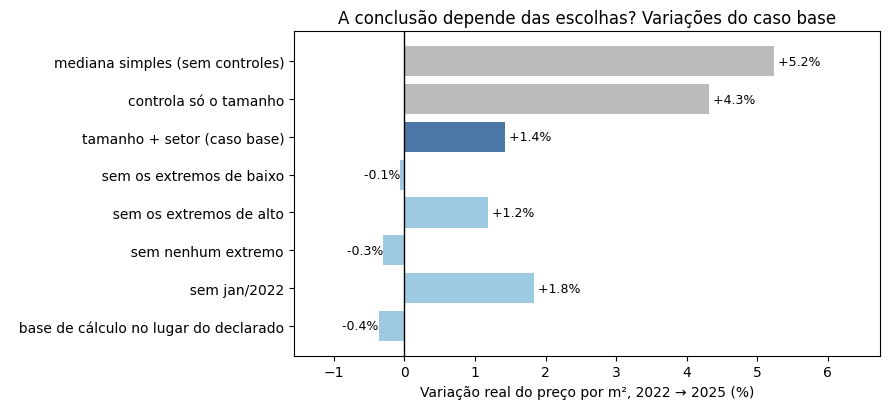

In [10]:
cores = ["#BBBBBB"] * 2 + ["#4C78A8"] + ["#9ECAE1"] * 5
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(sensibilidade.index, sensibilidade.values, color=cores)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=1)
for i, v in enumerate(sensibilidade.values):
    ax.text(v, i, f" {v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(sensibilidade.min() - 1.2, sensibilidade.max() + 1.5)
ax.set_xlabel("Variação real do preço por m², 2022 → 2025 (%)")
ax.set_title("A conclusão depende das escolhas? Variações do caso base")
plt.tight_layout()
plt.show()

## 7. Índice trimestral

Para ver o comportamento **dentro** dos anos, repetimos o índice de tamanho e setor por trimestre, com intervalo de 95%. O primeiro trimestre vale 100, e o último (2025Q4) tem só dois meses (out e nov), mas isso afeta pouco um índice de preços, que não depende da contagem de transações.

> O primeiro trimestre é a **base** do índice. Se ele estiver fora da linha por efeito de borda, todo o resto aparece deslocado.

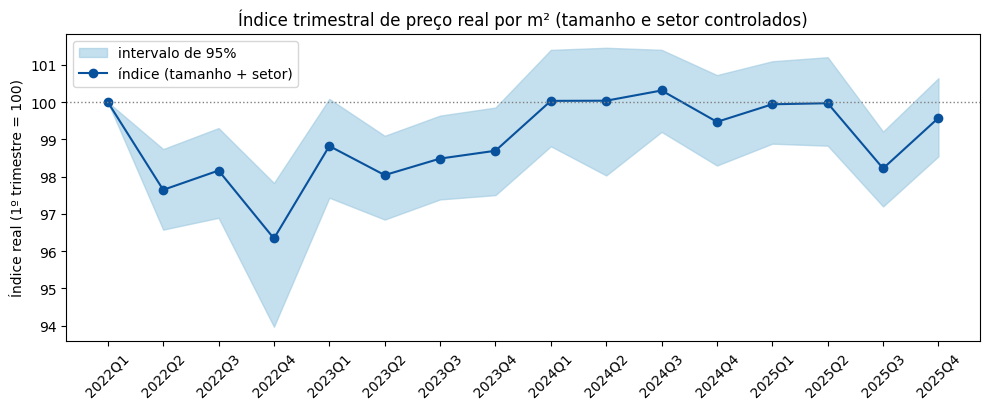

In [11]:
indice_trim = indice(df, "trimestre")
boot_trim = bootstrap_setores(df, "trimestre", repeticoes=100)
ic_trim = boot_trim.quantile([0.025, 0.975]).T
ic_trim.columns = ["inferior", "superior"]

fig, ax = plt.subplots(figsize=(10, 4.2))
x = range(len(indice_trim))
ax.fill_between(x, ic_trim["inferior"], ic_trim["superior"], color="#9ECAE1", alpha=0.6, label="intervalo de 95%")
ax.plot(x, indice_trim.values, marker="o", color="#08519C", label="índice (tamanho + setor)")
ax.axhline(100, color="gray", linestyle=":", linewidth=1)
ax.set_xticks(list(x))
ax.set_xticklabels(indice_trim.index, rotation=45)
ax.set_ylabel("Índice real (1º trimestre = 100)")
ax.set_title("Índice trimestral de preço real por m² (tamanho e setor controlados)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Gravar os resultados no banco

Gravamos o índice anual e o trimestral (com intervalos de confiança) e a tabela de sensibilidade em tabelas do esquema `analytics`, para o Power BI ler.

In [12]:
import pandas as pd

agora = pd.Timestamp.now().floor("s")

res_anual = (
    comparacao.join(ic_anual[["limite inferior", "limite superior"]])
    .rename(columns={
        "mediana simples": "mediana_simples",
        "controla tamanho": "controla_tamanho",
        "controla tamanho e setor": "controla_tamanho_setor",
        "limite inferior": "ic_inferior",
        "limite superior": "ic_superior",
    })
    .rename_axis("ano")
    .reset_index()
)

res_trim = pd.DataFrame({
    "trimestre": indice_trim.index,
    "indice": indice_trim.values,
    "ic_inferior": ic_trim["inferior"].reindex(indice_trim.index).values,
    "ic_superior": ic_trim["superior"].reindex(indice_trim.index).values,
})

res_sens = sensibilidade.rename_axis("variante").rename("variacao_pct").reset_index()
res_sens["variante"] = res_sens["variante"].str.strip()

resultados = {
    "res_indice_anual": res_anual,
    "res_indice_trimestral": res_trim,
    "res_sensibilidade_indice": res_sens,
}
for nome, tabela in resultados.items():
    tabela["gerado_em"] = agora
    tabela.to_sql(nome, engine, schema="analytics", if_exists="replace", index=False)
    print(f"analytics.{nome}: {len(tabela)} linhas")

analytics.res_indice_anual: 4 linhas
analytics.res_indice_trimestral: 16 linhas
analytics.res_sensibilidade_indice: 8 linhas
